Mercado de referência: ^BVSP | 2014-09-18 -> 2026-11-24 | 2948 dias

PARTE 1 -- CADEIA DE MARKOV SIMPLES (Bull/Bear observável)
Regra: Bull se retorno acumulado dos últimos 63 pregões > 0.  N = 2886 dias

Matriz de transição P  (linha = hoje, coluna = amanhã)
        Bear    Bull
Bear  0.9419  0.0581
Bull  0.0359  0.9641

Teste da propriedade de Markov (ordem 1 vs 2): G = 86.09, p-valor = 0.0000 -> REJEITA H0
  (H0: o passado além de hoje não acrescenta informação sobre amanhã)

Distribuição estacionária: Bear = 38.2% | Bull = 61.8%
Duração esperada:          Bear = 17.2 dias | Bull = 27.9 dias

Estado atual: Bear.  Previsão via P^k (Chapman-Kolmogorov):
  daqui a  1 dias: P(Bear) = 94.2% | P(Bull) = 5.8%
  daqui a  5 dias: P(Bear) = 75.9% | P(Bull) = 24.1%
  daqui a 21 dias: P(Bear) = 45.9% | P(Bull) = 54.1%
  daqui a 63 dias: P(Bear) = 38.3% | P(Bull) = 61.7%

Retornos diários por regime observável:
  ('mesmo dia' é viesado: o estado em t é definido usando o próprio retorno de t;
   

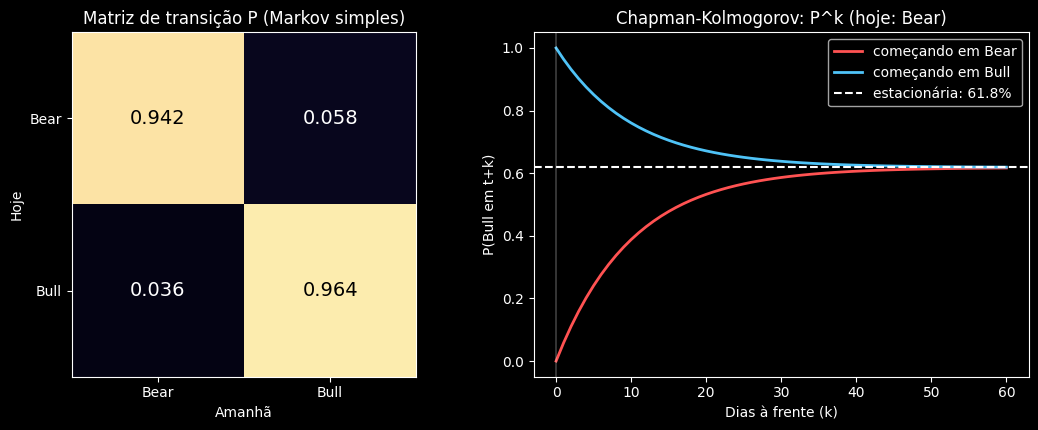

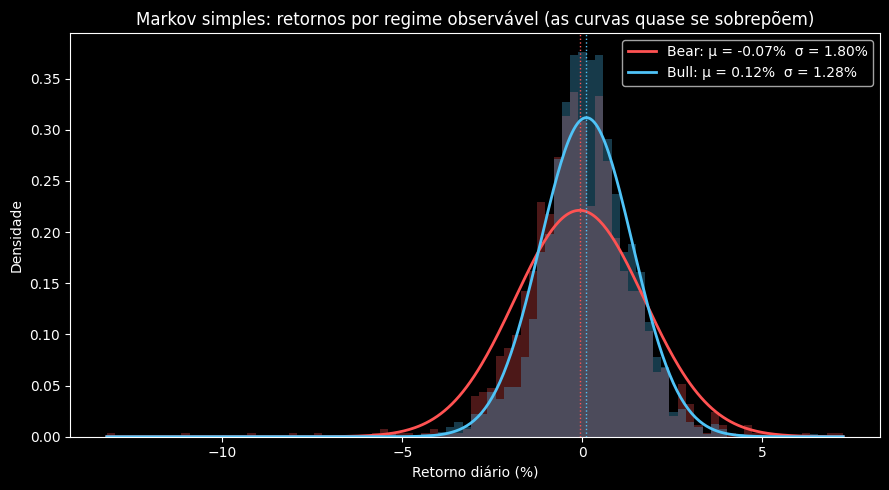

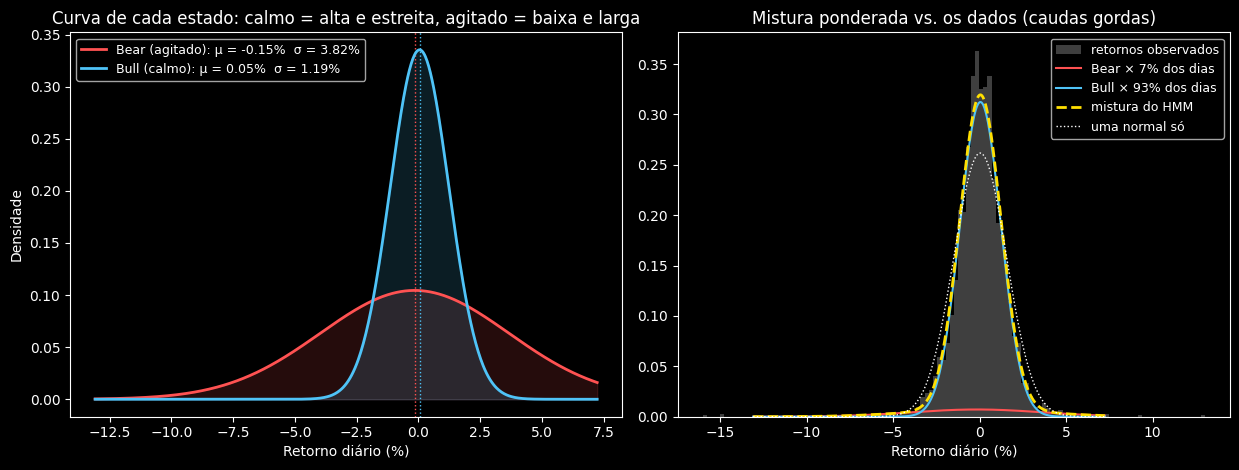

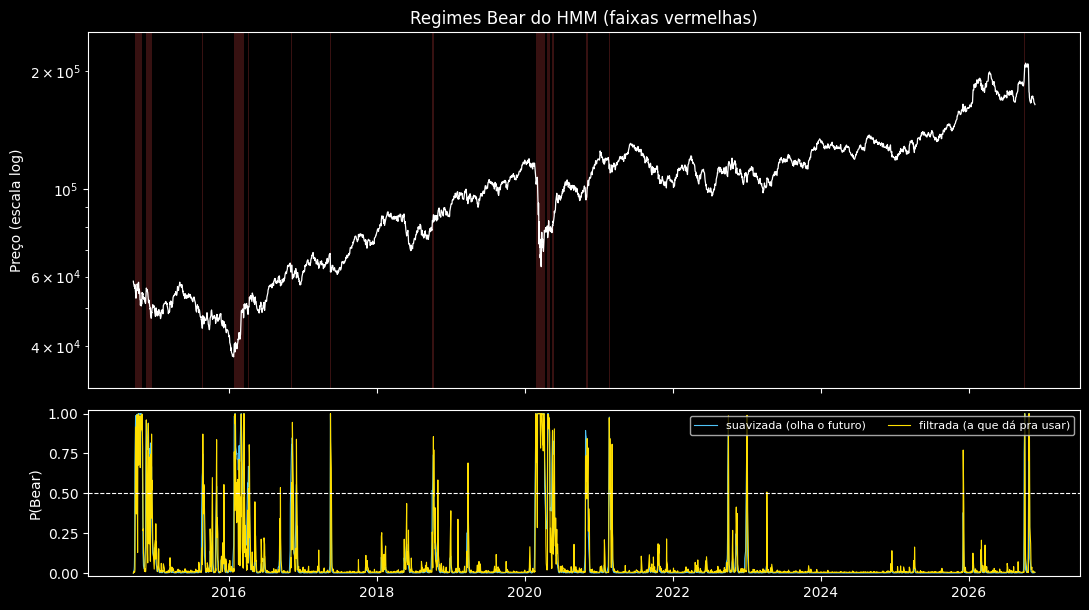

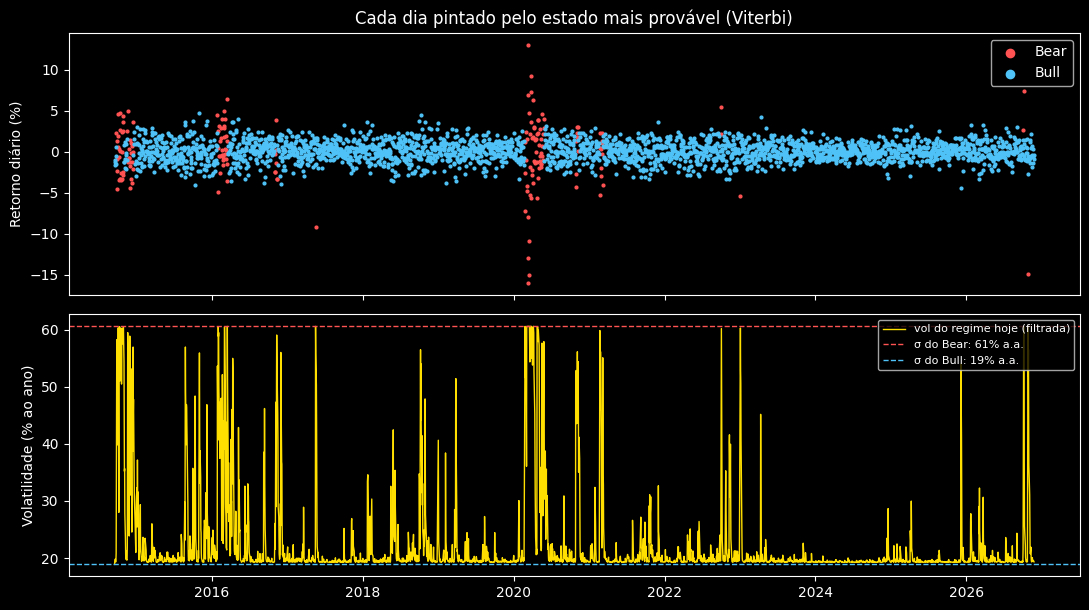

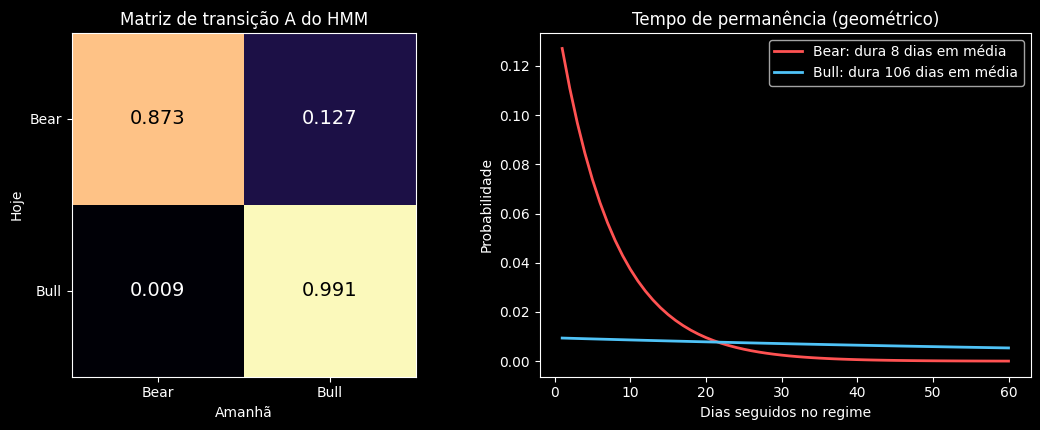

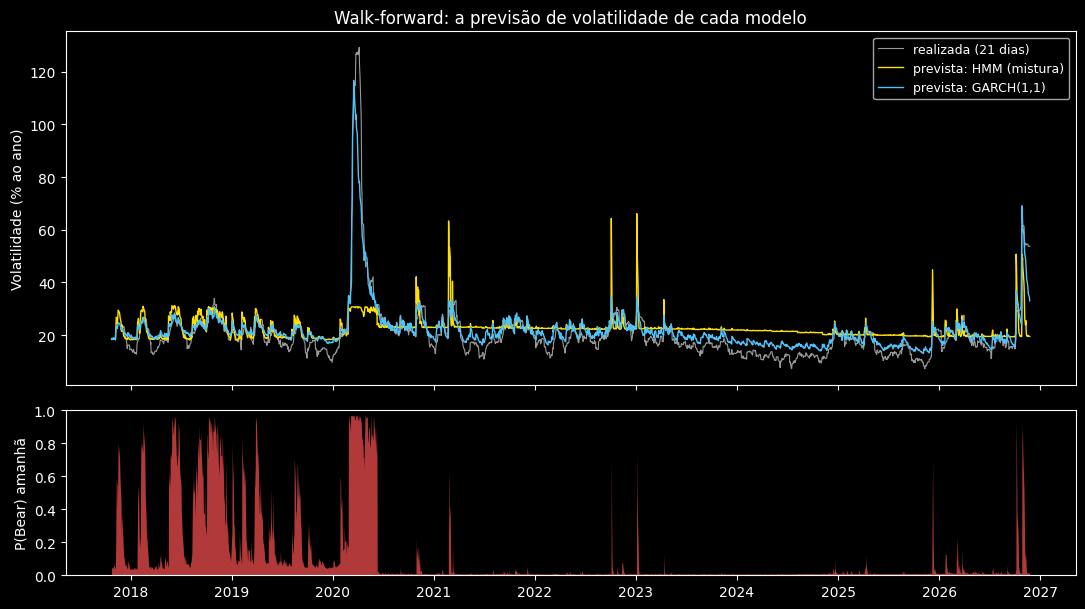

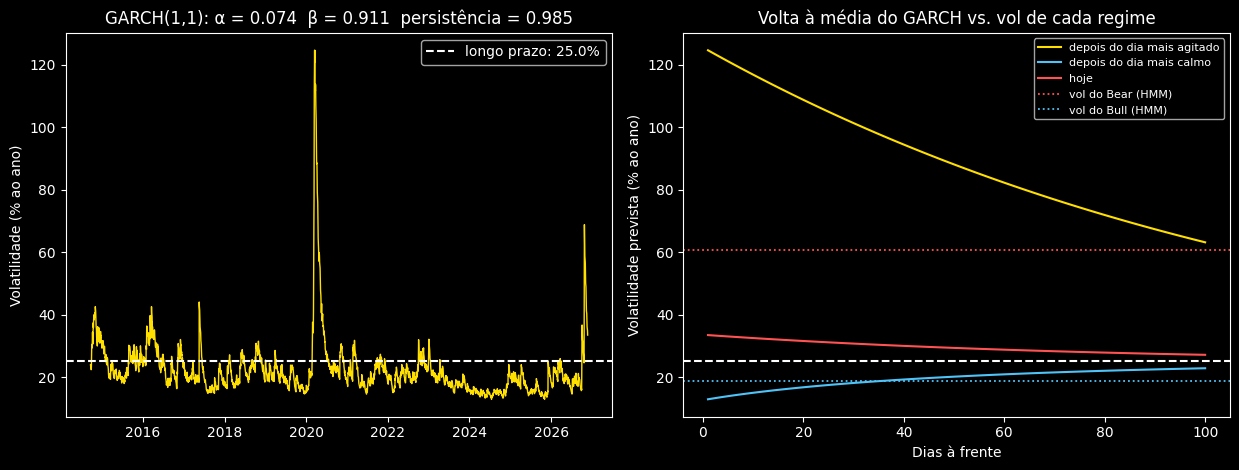

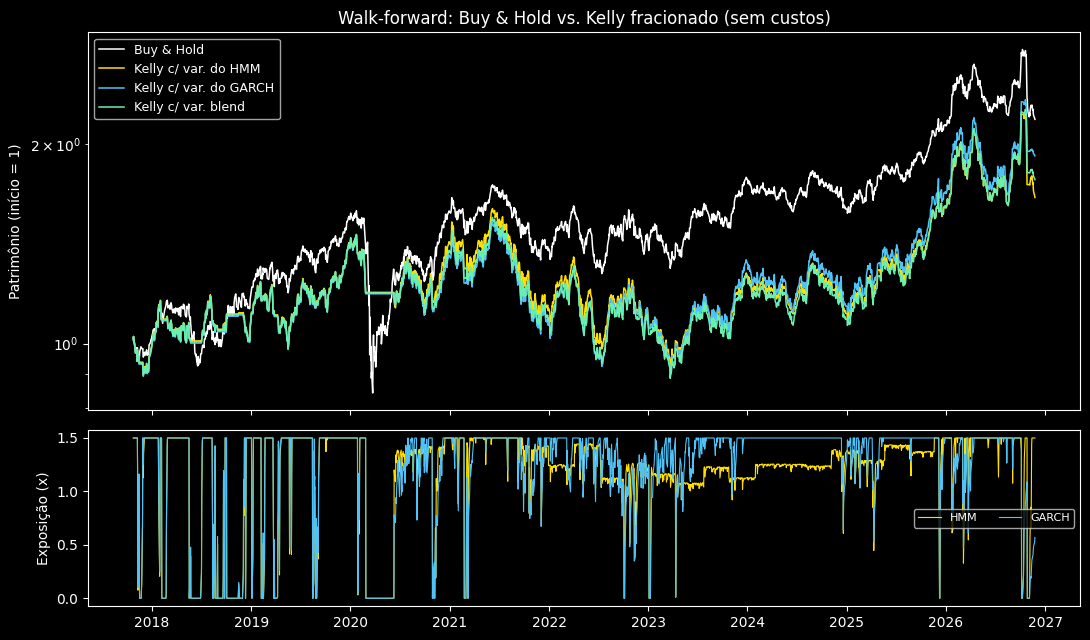

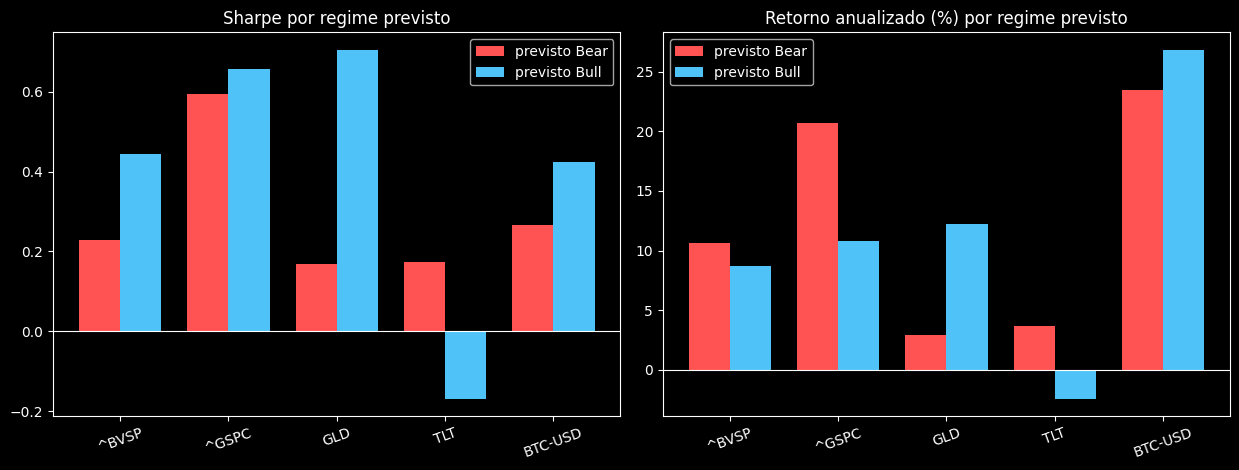


Gráficos salvos em: /content/plots_markov


In [3]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Regimes de mercado (Bull / Bear) com Cadeia de Markov + HMM

 Parte 1  Cadeia de Markov simples (estado OBSERVÁVEL: bull/bear por tendência)
          - matriz de transição P estimada por contagem
          - teste da propriedade de Markov (ordem 1 vs ordem 2, razão de verossimilhança)
          - Chapman-Kolmogorov: P^k  -> distribuição do estado daqui a k dias
          - distribuição estacionária e duração esperada de cada regime
 Parte 2  Hidden Markov Model (estado LATENTE) com emissões gaussianas
          - cada estado tem sua própria curva normal de retornos N(mu_k, sigma_k^2)
          - Baum-Welch (EM) implementado em numpy (sem hmmlearn), forward/backward, Viterbi
          - probabilidade FILTRADA (sem olhar o futuro) -> previsão do estado do dia seguinte
 Parte 3  Camada de volatilidade e dimensionamento
          - GARCH(1,1) (MLE via scipy)
          - Kelly fracionado usando a média/variância previstas (mistura do HMM e/ou GARCH)
          - Backtest walk-forward (refit periódico, sem look-ahead)
          - (Heston: ponto de extensão, veja o fim do arquivo)
 Parte 4  Desempenho histórico de cada ativo em cada regime
 Parte 5  Gráficos (por padrão; --no-plot desliga): bells do Markov e do HMM, regimes, volatilidade, GARCH, Kelly, ativos
"""
from __future__ import annotations

import argparse
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.signal import lfilter
from scipy.stats import chi2, norm

warnings.filterwarnings("ignore", category=RuntimeWarning)

TRADING_DAYS = 252
BEAR, BULL = 0, 1
STATE_NAMES = {BEAR: "Bear", BULL: "Bull"}


# Dados
def load_prices(tickers: list[str], start: str, end: str | None = None,
                market: str | None = None) -> pd.DataFrame | None:
    """Baixa preços ajustados via yfinance e alinha tudo ao calendário do `market`.
    Retorna None se algo falhar."""
    try:
        import yfinance as yf

        df = yf.download(tickers, start=start, end=end, auto_adjust=True, progress=False)["Close"]
        if isinstance(df, pd.Series):
            df = df.to_frame(tickers[0])
        df = align_calendar(df[tickers], market)
        if df.empty:
            raise ValueError("DataFrame vazio")
        return df
    except Exception as exc:  # noqa: BLE001
        print(f"[aviso] não consegui baixar dados ({exc}).")
        return None


def align_calendar(df: pd.DataFrame, market: str | None) -> pd.DataFrame:
    """Mantém só os dias em que o mercado de referência negociou e descarta datas com preço faltando.
    NÃO preenche (ffill): preencher fins de semana/feriados cria retornos exatamente zero, que o HMM
    "aprende" como um regime falso (σ≈0). Ativos 24/7 (ex.: BTC-USD) passam a ter retornos multi-dia
    nas segundas, o que é correto."""
    if market is not None:
        df = df[df[market].notna()]
    return df.dropna()


def check_data(rets: pd.DataFrame, limite: float = 0.02) -> None:
    """Avisa se algum ativo tem muitos retornos exatamente zero (calendário desalinhado ou dado preenchido)."""
    z = (rets == 0).mean()
    ruins = z[z > limite]
    if len(ruins):
        print("[ATENÇÃO] muitos retornos exatamente zero (calendário desalinhado ou dado preenchido):")
        print((100 * ruins).round(1).astype(str).add("%").to_string())
        print("          o HMM pode criar um 'regime' falso para esses dias. Revise os dados antes de concluir.")


def synthetic_prices(n: int = 3500, seed: int = 7) -> pd.DataFrame:
    """Simula um mercado com 2 regimes ocultos e 4 ativos com comportamento diferente em cada um."""
    rng = np.random.default_rng(seed)
    A = np.array([[0.94, 0.06],   # Bear -> Bear/Bull
                  [0.015, 0.985]])  # Bull -> Bear/Bull
    state = np.zeros(n, dtype=int)
    state[0] = BULL
    for t in range(1, n):
        state[t] = rng.choice(2, p=A[state[t - 1]])

    # (mu diário, sigma diário, correlação com o fator de mercado) por regime
    spec = {
        "MERCADO": {BEAR: (-0.0010, 0.022, 1.0), BULL: (0.0007, 0.007, 1.0)},
        "OURO":    {BEAR: (0.0006, 0.010, -0.2), BULL: (0.0002, 0.008, 0.1)},
        "TITULOS": {BEAR: (0.0004, 0.005, -0.4), BULL: (0.0001, 0.004, 0.0)},
        "CRIPTO":  {BEAR: (-0.0030, 0.050, 0.6), BULL: (0.0020, 0.030, 0.5)},
    }
    z = rng.standard_normal(n)  # fator comum
    data = {}
    for name, s in spec.items():
        mu = np.array([s[k][0] for k in state])
        sg = np.array([s[k][1] for k in state])
        rho = np.array([s[k][2] for k in state])
        eps = rng.standard_normal(n)
        data[name] = mu + sg * (rho * z + np.sqrt(1 - rho ** 2) * eps)
    rets = pd.DataFrame(data, index=pd.bdate_range("2012-01-02", periods=n))
    return 100 * np.exp(rets.cumsum())

# PARTE 1 -- Cadeia de Markov simples (estados observáveis)
def label_regimes_trend(returns: pd.Series, window: int = 63) -> pd.Series:
    """Regra observável: Bull se o retorno acumulado dos últimos `window` pregões > 0, senão Bear.
    Atenção: janelas sobrepostas tornam os rótulos MUITO persistentes (viés a favor de P_ii alto)."""
    trend = returns.rolling(window).sum()
    states = (trend > 0).astype(int)  # 1 = BULL, 0 = BEAR
    return states[trend.notna()]


def estimate_transition_matrix(states: np.ndarray, n_states: int = 2, laplace: float = 0.0) -> np.ndarray:
    """P[i, j] = P(X_{t+1}=j | X_t=i), por máxima verossimilhança (contagem)."""
    s = np.asarray(states, dtype=int)
    counts = np.zeros((n_states, n_states))
    np.add.at(counts, (s[:-1], s[1:]), 1)
    counts += laplace
    return counts / counts.sum(axis=1, keepdims=True)


def markov_property_test(states: np.ndarray, n_states: int = 2) -> tuple[float, float]:
    """Testa H0: P(X_{t+1} | X_t, X_{t-1}) = P(X_{t+1} | X_t)  (propriedade de Markov de 1ª ordem).
    Estatística G = 2 * sum n_ijk * ln( p(k|i,j) / p(k|j) ) ~ chi2 com S*(S-1)^2 gl."""
    s = np.asarray(states, dtype=int)
    n3 = np.zeros((n_states,) * 3)
    np.add.at(n3, (s[:-2], s[1:-1], s[2:]), 1)
    n_ij = n3.sum(axis=2, keepdims=True)
    n_jk = n3.sum(axis=0, keepdims=True)
    n_j = n3.sum(axis=(0, 2), keepdims=True)
    with np.errstate(divide="ignore", invalid="ignore"):
        p2 = n3 / n_ij
        p1 = n_jk / n_j
        terms = np.where(n3 > 0, n3 * np.log(p2 / p1), 0.0)
    g = 2.0 * terms.sum()
    df = n_states * (n_states - 1) ** 2
    return float(g), float(chi2.sf(g, df))


def stationary_distribution(P: np.ndarray) -> np.ndarray:
    """pi tal que pi P = pi (autovetor à esquerda associado ao autovalor 1)."""
    vals, vecs = np.linalg.eig(P.T)
    v = np.real(vecs[:, np.argmin(np.abs(vals - 1))])
    return v / v.sum()


def expected_duration(P: np.ndarray) -> np.ndarray:
    """Duração esperada (dias) de cada regime: 1 / (1 - P_ii)  (tempo de permanência é geométrico)."""
    return 1.0 / (1.0 - np.diag(P))


def k_step_forecast(P: np.ndarray, current_state: int, k: int) -> np.ndarray:
    """Chapman-Kolmogorov: distribuição do estado em t+k dado o estado atual = e_i P^k."""
    return np.linalg.matrix_power(P, k)[current_state]


def run_markov_chain(returns: pd.Series, window: int) -> tuple[np.ndarray, pd.Series]:
    print("\n" + "=" * 78)
    print("PARTE 1 -- CADEIA DE MARKOV SIMPLES (Bull/Bear observável)")
    print("=" * 78)
    states = label_regimes_trend(returns, window)
    s = states.values
    P = estimate_transition_matrix(s)
    print(f"Regra: Bull se retorno acumulado dos últimos {window} pregões > 0.  N = {len(s)} dias")
    print("\nMatriz de transição P  (linha = hoje, coluna = amanhã)")
    print(pd.DataFrame(P, index=["Bear", "Bull"], columns=["Bear", "Bull"]).round(4).to_string())

    g, pval = markov_property_test(s)
    verdict = "NÃO rejeita" if pval > 0.05 else "REJEITA"
    print(f"\nTeste da propriedade de Markov (ordem 1 vs 2): G = {g:.2f}, p-valor = {pval:.4f} -> {verdict} H0")
    print("  (H0: o passado além de hoje não acrescenta informação sobre amanhã)")

    pi = stationary_distribution(P)
    dur = expected_duration(P)
    print(f"\nDistribuição estacionária: Bear = {pi[BEAR]:.1%} | Bull = {pi[BULL]:.1%}")
    print(f"Duração esperada:          Bear = {dur[BEAR]:.1f} dias | Bull = {dur[BULL]:.1f} dias")

    cur = int(s[-1])
    print(f"\nEstado atual: {STATE_NAMES[cur]}.  Previsão via P^k (Chapman-Kolmogorov):")
    for k in (1, 5, 21, 63):
        d = k_step_forecast(P, cur, k)
        print(f"  daqui a {k:>2d} dias: P(Bear) = {d[BEAR]:.1%} | P(Bull) = {d[BULL]:.1%}")

    r = returns.loc[states.index]
    r_next = returns.shift(-1).loc[states.index]  # retorno do DIA SEGUINTE ao estado
    print("\nRetornos diários por regime observável:")
    print("  ('mesmo dia' é viesado: o estado em t é definido usando o próprio retorno de t;")
    print("   o teste preditivo honesto é o retorno de t+1 dado o estado em t)")
    tab = pd.DataFrame({
        STATE_NAMES[k]: {"média (mesmo dia)": r[s == k].mean(), "média (dia seguinte)": r_next[s == k].mean(),
                         "desvio (mesmo dia)": r[s == k].std(), "dias": int((s == k).sum())}
        for k in (BEAR, BULL)
    })
    print(tab.round(5).to_string())
    return P, states

# PARTE 2 -- Hidden Markov Model gaussiano (Baum-Welch em numpy)
class GaussianHMM:
    """HMM com K estados e emissão N(mu_k, sigma_k^2) para o retorno diário.
    Estados são reordenados por média crescente: índice 0 = Bear, último = Bull."""

    def __init__(self, n_states: int = 2, n_iter: int = 300, tol: float = 1e-7, min_sigma: float = 1e-4):
        self.K, self.n_iter, self.tol, self.min_sigma = n_states, n_iter, tol, min_sigma
        self.pi = self.A = self.mu = self.sigma = None
        self.loglik_ = -np.inf

    # ---- emissões / forward / backward (versão escalada, estável numericamente) ----
    def _emission(self, x: np.ndarray) -> np.ndarray:
        B = norm.pdf(x[:, None], self.mu[None, :], self.sigma[None, :])
        return np.maximum(B, 1e-300)

    def _forward(self, B: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        T, K = B.shape
        alpha, c = np.zeros((T, K)), np.zeros(T)
        a = self.pi * B[0]
        c[0] = a.sum()
        alpha[0] = a / c[0]
        for t in range(1, T):
            a = (alpha[t - 1] @ self.A) * B[t]
            c[t] = a.sum()
            alpha[t] = a / c[t]
        return alpha, c

    def _backward(self, B: np.ndarray, c: np.ndarray) -> np.ndarray:
        T, K = B.shape
        beta = np.ones((T, K))
        for t in range(T - 2, -1, -1):
            beta[t] = (self.A @ (B[t + 1] * beta[t + 1])) / c[t + 1]
        return beta

    # ---- treino (EM) ----
    def fit(self, x: np.ndarray) -> "GaussianHMM":
        x = np.asarray(x, dtype=float)
        m, s = x.mean(), x.std()
        self._sig_min = max(self.min_sigma, 0.2 * s)  # piso relativo: impede estado degenerado (σ→0)
        K = self.K
        # inicialização que quebra a simetria: estados diferem em média e, principalmente, em vol
        self.mu = m + s * np.linspace(-0.2, 0.2, K)
        self.sigma = s * np.linspace(1.6, 0.6, K)
        self.A = np.full((K, K), 0.05 / max(K - 1, 1))
        np.fill_diagonal(self.A, 0.95)
        self.pi = np.full(K, 1.0 / K)

        prev = -np.inf
        for _ in range(self.n_iter):
            B = self._emission(x)
            alpha, c = self._forward(B)
            beta = self._backward(B, c)
            ll = np.log(c).sum()

            gamma = alpha * beta                                   # P(S_t = k | x_1..T)
            W = B[1:] * beta[1:] / c[1:, None]
            xi_sum = self.A * (alpha[:-1].T @ W)                   # sum_t P(S_t=i, S_{t+1}=j | x)

            self.pi = gamma[0] / gamma[0].sum()
            self.A = xi_sum / xi_sum.sum(axis=1, keepdims=True)
            g_sum = gamma.sum(axis=0)
            self.mu = (gamma * x[:, None]).sum(axis=0) / g_sum
            var = (gamma * (x[:, None] - self.mu) ** 2).sum(axis=0) / g_sum
            self.sigma = np.sqrt(np.maximum(var, self._sig_min ** 2))

            if abs(ll - prev) < self.tol * (1 + abs(ll)):
                break
            prev = ll
        self.loglik_ = ll
        self._sort_states()
        return self

    def _sort_states(self) -> None:
        order = np.argsort(self.mu)  # Bear (menor média) ... Bull (maior média)
        self.mu, self.sigma, self.pi = self.mu[order], self.sigma[order], self.pi[order]
        self.A = self.A[np.ix_(order, order)]

    # ---- inferência ----
    def filtered_probs(self, x: np.ndarray) -> np.ndarray:
        """P(S_t | x_1..t): usa só informação disponível em t (sem look-ahead). Use para PREVER."""
        return self._forward(self._emission(np.asarray(x, dtype=float)))[0]

    def smoothed_probs(self, x: np.ndarray) -> np.ndarray:
        """P(S_t | x_1..T): usa a amostra inteira (tem look-ahead). Use só para ANÁLISE descritiva."""
        B = self._emission(np.asarray(x, dtype=float))
        alpha, c = self._forward(B)
        return alpha * self._backward(B, c)

    def viterbi(self, x: np.ndarray) -> np.ndarray:
        """Sequência de estados mais provável (global)."""
        B = np.log(self._emission(np.asarray(x, dtype=float)))
        logA, T, K = np.log(self.A), len(x), self.K
        delta, psi = np.zeros((T, K)), np.zeros((T, K), dtype=int)
        delta[0] = np.log(self.pi) + B[0]
        for t in range(1, T):
            cand = delta[t - 1][:, None] + logA
            psi[t] = cand.argmax(axis=0)
            delta[t] = cand.max(axis=0) + B[t]
        path = np.zeros(T, dtype=int)
        path[-1] = delta[-1].argmax()
        for t in range(T - 2, -1, -1):
            path[t] = psi[t + 1, path[t + 1]]
        return path

    # ---- previsão do próximo dia ----
    def predict_next_state(self, alpha_t: np.ndarray) -> np.ndarray:
        """P(S_{t+1} | x_1..t) = alpha_t @ A."""
        return np.atleast_2d(alpha_t) @ self.A

    def mixture_moments(self, p_next: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        """Média e variância do retorno de amanhã sob a mistura de gaussianas ponderada por p_next."""
        p = np.atleast_2d(p_next)
        mu_mix = p @ self.mu
        var_mix = p @ (self.sigma ** 2 + self.mu ** 2) - mu_mix ** 2
        return mu_mix, var_mix

    def mixture_logpdf(self, p_next: np.ndarray, x: np.ndarray) -> np.ndarray:
        dens = (np.atleast_2d(p_next) * norm.pdf(np.asarray(x)[:, None], self.mu, self.sigma)).sum(axis=1)
        return np.log(np.maximum(dens, 1e-300))


def run_hmm(returns: pd.Series, markov_states: pd.Series) -> tuple[GaussianHMM, pd.DataFrame]:
    print("\n" + "=" * 78)
    print("PARTE 2 -- HIDDEN MARKOV MODEL (2 estados, emissão gaussiana)")
    print("=" * 78)
    x = returns.values
    hmm = GaussianHMM(2).fit(x)

    print(f"Log-verossimilhança: {hmm.loglik_:.1f}")
    print("\nCurva de retornos de cada estado (a curva 'wild' é MAIS LARGA e mais baixa no pico):")
    tab = pd.DataFrame({
        STATE_NAMES[k]: {
            "mu diário": hmm.mu[k], "sigma diário": hmm.sigma[k],
            "retorno anualizado": hmm.mu[k] * TRADING_DAYS,
            "vol anualizada": hmm.sigma[k] * np.sqrt(TRADING_DAYS),
            "pico da densidade": norm.pdf(hmm.mu[k], hmm.mu[k], hmm.sigma[k]),
        } for k in (BEAR, BULL)
    })
    print(tab.round(5).to_string())

    print("\nMatriz de transição do HMM (estados LATENTES):")
    print(pd.DataFrame(hmm.A, index=["Bear", "Bull"], columns=["Bear", "Bull"]).round(4).to_string())
    print(f"Duração esperada: Bear = {expected_duration(hmm.A)[BEAR]:.1f} d | Bull = {expected_duration(hmm.A)[BULL]:.1f} d")

    alpha = hmm.filtered_probs(x)
    smooth = hmm.smoothed_probs(x)
    p_next = hmm.predict_next_state(alpha[-1])[0]
    mu_m, var_m = hmm.mixture_moments(p_next)
    print(f"\nHoje ({returns.index[-1].date()}): P(Bear) = {alpha[-1][BEAR]:.1%} | P(Bull) = {alpha[-1][BULL]:.1%}")
    print(f"Amanhã (filtrado @ A):      P(Bear) = {p_next[BEAR]:.1%} | P(Bull) = {p_next[BULL]:.1%}")
    print(f"Retorno esperado amanhã: {mu_m[0]:+.4%} | vol esperada (mistura): {np.sqrt(var_m[0]):.3%} ao dia "
          f"({np.sqrt(var_m[0] * TRADING_DAYS):.1%} a.a.)")

    smooth_state = pd.Series(smooth.argmax(axis=1), index=returns.index)
    agree = float((smooth_state.loc[markov_states.index] == markov_states).mean())
    print(f"Concordância HMM(smoothed) vs regra de tendência: {agree:.1%}  "
          "(o HMM separa por volatilidade/média, a regra por tendência -> não precisam coincidir)")

    out = pd.DataFrame({"p_bear_filt": alpha[:, BEAR], "p_bull_filt": alpha[:, BULL],
                        "p_bear_smooth": smooth[:, BEAR], "p_bull_smooth": smooth[:, BULL],
                        "viterbi": hmm.viterbi(x)}, index=returns.index)
    return hmm, out


# PARTE 3 -- GARCH(1,1), Kelly e backtest walk-forward
class GARCH11:
    """r_t = mu + e_t,  e_t ~ N(0, h_t),  h_t = omega + alpha e_{t-1}^2 + beta h_{t-1}  (MLE gaussiano)."""

    def fit(self, r: np.ndarray) -> "GARCH11":
        y = np.asarray(r, dtype=float) * 100.0  # escala melhora a otimização
        v0 = y.var()

        def nll(p):
            mu, om, a, b = p
            e = y - mu
            h = self._filter(e, om, a, b, v0)
            return 0.5 * np.sum(np.log(h) + e ** 2 / h)

        x0 = [y.mean(), 0.05 * v0, 0.08, 0.90]
        res = minimize(nll, x0, method="SLSQP",
                       bounds=[(-5, 5), (1e-6, None), (1e-6, 0.5), (0.0, 0.9995)],
                       constraints=[{"type": "ineq", "fun": lambda p: 0.9999 - p[2] - p[3]}])
        mu, om, a, b = res.x
        self.mu, self.omega, self.alpha, self.beta = mu / 100.0, om / 1e4, a, b
        self.var0 = float(np.var(r))
        return self

    @staticmethod
    def _filter(e: np.ndarray, om: float, a: float, b: float, v0: float) -> np.ndarray:
        u = np.empty_like(e)
        u[0] = v0
        u[1:] = om + a * e[:-1] ** 2
        return lfilter([1.0], [1.0, -b], u)  # h_t = b h_{t-1} + u_t

    def next_variance(self, r: np.ndarray) -> np.ndarray:
        """Para cada t: previsão de Var(r_{t+1} | info até t)  (usa só dados até t)."""
        e = np.asarray(r, dtype=float) - self.mu
        h = self._filter(e, self.omega, self.alpha, self.beta, self.var0)
        return self.omega + self.alpha * e ** 2 + self.beta * h

    @property
    def persistence(self) -> float:
        return self.alpha + self.beta


def kelly_fraction(mu: np.ndarray, var: np.ndarray, fraction: float = 0.5,
                   max_leverage: float = 1.5, rf_daily: float = 0.0) -> np.ndarray:
    """Kelly contínuo f* = (mu - rf) / sigma^2, fracionado e limitado a [0, max_leverage] (long-only)."""
    f = fraction * (mu - rf_daily) / np.maximum(var, 1e-10)
    return np.clip(f, 0.0, max_leverage)


def perf_stats(simple_ret: pd.Series) -> dict:
    eq = (1 + simple_ret).cumprod()
    n = len(simple_ret)
    return {
        "retorno a.a.": eq.iloc[-1] ** (TRADING_DAYS / n) - 1,
        "vol a.a.": simple_ret.std() * np.sqrt(TRADING_DAYS),
        "Sharpe": simple_ret.mean() / simple_ret.std() * np.sqrt(TRADING_DAYS) if simple_ret.std() > 0 else np.nan,
        "max drawdown": (eq / eq.cummax() - 1).min(),
        "riqueza final": eq.iloc[-1],
    }


def walk_forward(returns: pd.Series, min_train: int = 750, refit_every: int = 63,
                 kelly_frac: float = 0.5, max_lev: float = 1.5) -> pd.DataFrame:
    """A cada `refit_every` dias reestima HMM e GARCH SÓ com o passado e gera, para cada dia t,
    as previsões de t+1 (estado, média, variância). Nada do futuro vaza para o treino."""
    r = returns.values
    T = len(r)
    rows = []
    for start in range(min_train, T - 1, refit_every):
        end = min(start + refit_every, T)
        hmm = GaussianHMM(2).fit(r[:start])
        gar = GARCH11().fit(r[:start])
        static_mu, static_sd = r[:start].mean(), r[:start].std()

        alpha = hmm.filtered_probs(r[:end])           # parâmetros fixos, filtro só olha para trás
        idx = np.arange(start - 1, end - 1)           # t: previsão feita no fim do dia t, alvo = t+1
        tgt = idx + 1
        p_next = hmm.predict_next_state(alpha[idx])
        mu_mix, var_mix = hmm.mixture_moments(p_next)
        var_gar = gar.next_variance(r[:end])[idx]
        x = r[tgt]

        rows.append(pd.DataFrame({
            "ret": x,
            "state_today": alpha[idx].argmax(axis=1),
            "state_pred": p_next.argmax(axis=1),
            "state_filt_next": alpha[tgt].argmax(axis=1),
            "p_bear_next": p_next[:, BEAR],
            "mu_hat": mu_mix, "var_hmm": var_mix, "var_garch": var_gar,
            "ll_static": norm.logpdf(x, static_mu, static_sd),
            "ll_hmm": hmm.mixture_logpdf(p_next, x),
            "ll_garch": norm.logpdf(x, gar.mu, np.sqrt(var_gar)),
        }, index=returns.index[tgt]))
    wf = pd.concat(rows)

    # posições (decididas em t, aplicadas ao retorno de t+1)
    wf["pos_hmm"] = kelly_fraction(wf["mu_hat"].values, wf["var_hmm"].values, kelly_frac, max_lev)
    wf["pos_garch"] = kelly_fraction(wf["mu_hat"].values, wf["var_garch"].values, kelly_frac, max_lev)
    wf["pos_blend"] = kelly_fraction(wf["mu_hat"].values, 0.5 * (wf["var_hmm"] + wf["var_garch"]).values, kelly_frac, max_lev)
    return wf


def run_walk_forward(returns: pd.Series, args) -> pd.DataFrame:
    print("\n" + "=" * 78)
    print("PARTE 3 -- PREVISÃO WALK-FORWARD, GARCH E KELLY")
    print("=" * 78)
    wf = walk_forward(returns, args.min_train, args.refit_every, args.kelly_frac, args.max_lev)
    print(f"Janela fora da amostra: {wf.index[0].date()} -> {wf.index[-1].date()}  ({len(wf)} dias)")
    print(f"Treino inicial = {args.min_train} dias, refit a cada {args.refit_every} dias (expanding window)")

    print("\n(a) Qualidade da previsão da DISTRIBUIÇÃO do retorno de amanhã (log-verossimilhança média; maior = melhor)")
    ll = pd.Series({"Gaussiana estática": wf["ll_static"].mean(),
                    "HMM (mistura de regimes)": wf["ll_hmm"].mean(),
                    "GARCH(1,1)": wf["ll_garch"].mean()})
    print(ll.round(4).to_string())

    acc = (wf["state_pred"] == wf["state_filt_next"]).mean()
    pers = (wf["state_today"] == wf["state_filt_next"]).mean()
    print(f"\n(b) Estado de amanhã: previsto vs. filtrado no dia seguinte = {acc:.1%} "
          f"(persistência ingênua 'amanhã = hoje': {pers:.1%})")
    print("    Com regimes tão persistentes, argmax(alpha @ A) quase sempre repete o estado de hoje;")
    print("    o ganho real do HMM está na PROBABILIDADE (p_bear_next) e na variância da mistura, não no rótulo.")

    print(f"\n(c) Estratégias (Kelly {args.kelly_frac:.0%}, alavancagem máx. {args.max_lev}x, long-only, sem custos)")
    simple = np.expm1(wf["ret"])
    strategies = {
        "Buy & Hold": simple,
        "Kelly c/ var. do HMM": wf["pos_hmm"] * simple,
        "Kelly c/ var. do GARCH": wf["pos_garch"] * simple,
        "Kelly c/ var. blend": wf["pos_blend"] * simple,
    }
    table = pd.DataFrame({k: perf_stats(v) for k, v in strategies.items()}).T
    print(table.round(3).to_string())
    print(f"\nExposição média: HMM {wf['pos_hmm'].mean():.2f}x | GARCH {wf['pos_garch'].mean():.2f}x | blend {wf['pos_blend'].mean():.2f}x")
    wf.attrs["strategies"] = strategies
    return wf


# =====================================================================================
# PARTE 4 -- Desempenho dos ativos por regime
# =====================================================================================
def regime_asset_table(asset_returns: pd.DataFrame, regime: pd.Series) -> pd.DataFrame:
    """Estatísticas anualizadas de cada ativo condicionadas ao regime (alinhado por data)."""
    df = asset_returns.join(regime.rename("regime"), how="inner")
    rows = []
    for k in (BEAR, BULL):
        sub = df[df["regime"] == k].drop(columns="regime")
        for a in sub.columns:
            r = sub[a]
            rows.append({
                "regime": STATE_NAMES[k], "ativo": a, "dias": len(r),
                "retorno a.a.": r.mean() * TRADING_DAYS,
                "vol a.a.": r.std() * np.sqrt(TRADING_DAYS),
                "Sharpe": r.mean() / r.std() * np.sqrt(TRADING_DAYS) if r.std() > 0 else np.nan,
                "% dias positivos": (r > 0).mean(),
                "pior dia": r.min(),
            })
    return pd.DataFrame(rows).set_index(["regime", "ativo"])


def run_asset_analysis(asset_rets: pd.DataFrame, hmm_out: pd.DataFrame, wf: pd.DataFrame) -> None:
    print("\n" + "=" * 78)
    print("PARTE 4 -- QUAIS ATIVOS FUNCIONAM MELHOR EM CADA REGIME?")
    print("=" * 78)

    desc = regime_asset_table(asset_rets, hmm_out["p_bull_smooth"].gt(0.5).astype(int))
    print("\n(a) DESCRITIVO: regime = estado suavizado do HMM em t (usa a amostra toda; serve para entender o passado)")
    print(desc.round(3).to_string())

    act = regime_asset_table(asset_rets.shift(0), wf["state_pred"])
    print("\n(b) ACIONÁVEL: regime previsto NO FECHAMENTO de t-1 (walk-forward), retorno do ativo em t")
    print(act.round(3).to_string())

    print("\nMelhor ativo por Sharpe (tabela acionável):")
    for k in (BEAR, BULL):
        s = act.loc[STATE_NAMES[k], "Sharpe"].sort_values(ascending=False)
        print(f"  {STATE_NAMES[k]}: " + " > ".join(f"{a} ({v:.2f})" for a, v in s.items()))


# PARTE 5 -- GRÁFICOS
AMARELO, AZUL, VERMELHO, VERDE = "#FFDF00", "#4FC3F7", "#FF5252", "#69F0AE"
COR_ESTADO = {BEAR: VERMELHO, BULL: AZUL}
_G = {"outdir": None, "mostrar": True}  # run_graficos() ajusta; no Colab basta deixar o padrão


def _fim(fig, nome: str) -> None:
    fig.tight_layout()
    if _G["outdir"]:
        os.makedirs(_G["outdir"], exist_ok=True)
        fig.savefig(os.path.join(_G["outdir"], nome + ".png"), dpi=130)
    if _G["mostrar"]:
        plt.show()
    else:
        plt.close(fig)


def _heatmap(a, M: np.ndarray, titulo: str) -> None:
    a.imshow(M, cmap="magma", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{M[i, j]:.3f}", ha="center", va="center", fontsize=14,
                   color="black" if M[i, j] > 0.5 else "white")
    a.set_xticks([0, 1]); a.set_xticklabels(["Bear", "Bull"])
    a.set_yticks([0, 1]); a.set_yticklabels(["Bear", "Bull"])
    a.set_xlabel("Amanhã"); a.set_ylabel("Hoje"); a.set_title(titulo)


def grafico_1_markov_matriz(P: np.ndarray, estado_atual: int, k_max: int = 60) -> None:
    """#Gráfico 1: matriz P e a convergência de P^k para a distribuição estacionária."""
    pi = stationary_distribution(P)
    fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.4))
    _heatmap(a, P, "Matriz de transição P (Markov simples)")

    M = np.eye(2)
    prob = {BEAR: [], BULL: []}
    for k in range(k_max + 1):
        for i in (BEAR, BULL):
            prob[i].append(M[i, BULL])
        M = M @ P
    for i in (BEAR, BULL):
        b.plot(prob[i], color=COR_ESTADO[i], lw=2, label=f"começando em {STATE_NAMES[i]}")
    b.axhline(pi[BULL], color="white", ls="--", label=f"estacionária: {pi[BULL]:.1%}")
    b.axvline(0, color="white", lw=0.3)
    b.set_xlabel("Dias à frente (k)"); b.set_ylabel("P(Bull em t+k)")
    b.set_title(f"Chapman-Kolmogorov: P^k (hoje: {STATE_NAMES[estado_atual]})")
    b.legend()
    _fim(fig, "g1_markov_matriz")


def grafico_2_markov_bell(returns: pd.Series, markov_states: pd.Series) -> None:
    """#Gráfico 2: curva de retornos de cada regime observável (Markov simples)."""
    r = 100 * returns.loc[markov_states.index]
    s = markov_states.values
    xs = np.linspace(r.quantile(0.001), r.quantile(0.999), 400)
    bins = np.linspace(xs[0], xs[-1], 90)

    fig, a = plt.subplots(figsize=(9, 5))
    for k in (BEAR, BULL):
        x = r[s == k]
        mu, sd = x.mean(), x.std()
        a.hist(x, bins=bins, density=True, color=COR_ESTADO[k], alpha=0.30)
        a.plot(xs, norm.pdf(xs, mu, sd), color=COR_ESTADO[k], lw=2,
               label=f"{STATE_NAMES[k]}: μ = {mu:.2f}%  σ = {sd:.2f}%")
        a.axvline(mu, color=COR_ESTADO[k], ls=":", lw=1)
    a.set_xlabel("Retorno diário (%)"); a.set_ylabel("Densidade")
    a.set_title("Markov simples: retornos por regime observável (as curvas quase se sobrepõem)")
    a.legend()
    _fim(fig, "g2_markov_bell")


def grafico_3_hmm_bell(returns: pd.Series, hmm: GaussianHMM, hmm_out: pd.DataFrame) -> None:
    """#Gráfico 3: a curva de sino de cada estado do HMM e a mistura que ela forma."""
    r = 100 * returns.values
    xs = np.linspace(np.quantile(r, 0.001), np.quantile(r, 0.999), 600)
    mu, sd = 100 * hmm.mu, 100 * hmm.sigma
    w = hmm_out[["p_bear_smooth", "p_bull_smooth"]].mean().values
    tipo = {k: ("calmo" if sd[k] == sd.min() else "agitado") for k in (BEAR, BULL)}

    fig, (a, b) = plt.subplots(1, 2, figsize=(12.5, 4.8))
    for k in (BEAR, BULL):
        d = norm.pdf(xs, mu[k], sd[k])
        a.plot(xs, d, color=COR_ESTADO[k], lw=2,
               label=f"{STATE_NAMES[k]} ({tipo[k]}): μ = {mu[k]:.2f}%  σ = {sd[k]:.2f}%")
        a.fill_between(xs, d, color=COR_ESTADO[k], alpha=0.15)
        a.axvline(mu[k], color=COR_ESTADO[k], ls=":", lw=1)
    a.set_xlabel("Retorno diário (%)"); a.set_ylabel("Densidade")
    a.set_title("Curva de cada estado: calmo = alta e estreita, agitado = baixa e larga")
    a.legend(fontsize=9)

    b.hist(r, bins=120, density=True, color="white", alpha=0.25, label="retornos observados")
    mist = np.zeros_like(xs)
    for k in (BEAR, BULL):
        d = w[k] * norm.pdf(xs, mu[k], sd[k])
        mist += d
        b.plot(xs, d, color=COR_ESTADO[k], lw=1.5, label=f"{STATE_NAMES[k]} × {w[k]:.0%} dos dias")
    b.plot(xs, mist, color=AMARELO, lw=2, ls="--", label="mistura do HMM")
    b.plot(xs, norm.pdf(xs, r.mean(), r.std()), color="white", lw=1, ls=":", label="uma normal só")
    b.set_xlabel("Retorno diário (%)")
    b.set_title("Mistura ponderada vs. os dados (caudas gordas)")
    b.legend(fontsize=9)
    _fim(fig, "g3_hmm_bell")


def grafico_4_hmm_regimes(precos: pd.Series, hmm_out: pd.DataFrame) -> None:
    """#Gráfico 4: preço com os regimes sombreados e a probabilidade de Bear ao longo do tempo."""
    fig, (a, b) = plt.subplots(2, 1, sharex=True, figsize=(11, 6.2),
                               gridspec_kw={"height_ratios": [3, 1.4]})
    a.plot(precos.index, precos.values, color="white", lw=0.9)
    a.set_yscale("log")
    bear = (hmm_out["p_bear_smooth"] > 0.5).values
    a.fill_between(precos.index, 0, 1, where=bear, transform=a.get_xaxis_transform(),
                   color=VERMELHO, alpha=0.22, lw=0)
    a.set_ylabel("Preço (escala log)")
    a.set_title("Regimes Bear do HMM (faixas vermelhas)")

    b.plot(hmm_out.index, hmm_out["p_bear_smooth"], color=AZUL, lw=0.8, label="suavizada (olha o futuro)")
    b.plot(hmm_out.index, hmm_out["p_bear_filt"], color=AMARELO, lw=0.8, label="filtrada (a que dá pra usar)")
    b.axhline(0.5, color="white", ls="--", lw=0.8)
    b.set_ylabel("P(Bear)"); b.set_ylim(-0.02, 1.02)
    b.legend(loc="upper right", fontsize=8, ncol=2)
    _fim(fig, "g4_hmm_regimes")


def grafico_5_hmm_vol(returns: pd.Series, hmm: GaussianHMM, hmm_out: pd.DataFrame) -> None:
    """#Gráfico 5: retornos coloridos pelo estado (Viterbi) e volatilidade do regime atual."""
    r = 100 * returns
    est = hmm_out["viterbi"].values
    anual = 100 * np.sqrt(TRADING_DAYS)
    sig = np.sqrt(hmm_out[["p_bear_filt", "p_bull_filt"]].values @ hmm.sigma ** 2)

    fig, (a, b) = plt.subplots(2, 1, sharex=True, figsize=(11, 6.2))
    for k in (BEAR, BULL):
        m = est == k
        a.scatter(r.index[m], r.values[m], s=4, color=COR_ESTADO[k], label=STATE_NAMES[k])
    a.set_ylabel("Retorno diário (%)")
    a.set_title("Cada dia pintado pelo estado mais provável (Viterbi)")
    a.legend(markerscale=3)

    b.plot(r.index, anual * sig, color=AMARELO, lw=1, label="vol do regime hoje (filtrada)")
    for k in (BEAR, BULL):
        b.axhline(anual * hmm.sigma[k], color=COR_ESTADO[k], ls="--", lw=1,
                  label=f"σ do {STATE_NAMES[k]}: {anual * hmm.sigma[k]:.0f}% a.a.")
    b.set_ylabel("Volatilidade (% ao ano)")
    b.legend(fontsize=8, loc="upper right")
    _fim(fig, "g5_hmm_vol")


def grafico_6_hmm_transicao(hmm: GaussianHMM, d_max: int = 60) -> None:
    """#Gráfico 6: matriz de transição do HMM e distribuição do tempo de permanência em cada regime."""
    fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.4))
    _heatmap(a, hmm.A, "Matriz de transição A do HMM")
    d = np.arange(1, d_max + 1)
    for k in (BEAR, BULL):
        p = hmm.A[k, k]
        b.plot(d, p ** (d - 1) * (1 - p), color=COR_ESTADO[k], lw=2,
               label=f"{STATE_NAMES[k]}: dura {1 / (1 - p):.0f} dias em média")
    b.set_xlabel("Dias seguidos no regime"); b.set_ylabel("Probabilidade")
    b.set_title("Tempo de permanência (geométrico)")
    b.legend()
    _fim(fig, "g6_hmm_transicao")


def grafico_7_vol_walk_forward(wf: pd.DataFrame) -> None:
    """#Gráfico 7: volatilidade prevista (HMM e GARCH) vs. realizada, fora da amostra."""
    real = 100 * wf["ret"].rolling(21).std() * np.sqrt(TRADING_DAYS)
    fig, (a, b) = plt.subplots(2, 1, sharex=True, figsize=(11, 6.2),
                               gridspec_kw={"height_ratios": [3, 1.4]})
    a.plot(real, color="white", lw=0.8, alpha=0.6, label="realizada (21 dias)")
    a.plot(100 * np.sqrt(TRADING_DAYS * wf["var_hmm"]), color=AMARELO, lw=1, label="prevista: HMM (mistura)")
    a.plot(100 * np.sqrt(TRADING_DAYS * wf["var_garch"]), color=AZUL, lw=1, label="prevista: GARCH(1,1)")
    a.set_ylabel("Volatilidade (% ao ano)")
    a.set_title("Walk-forward: a previsão de volatilidade de cada modelo")
    a.legend(fontsize=9)

    b.fill_between(wf.index, wf["p_bear_next"], color=VERMELHO, alpha=0.7, lw=0)
    b.set_ylim(0, 1); b.set_ylabel("P(Bear) amanhã")
    _fim(fig, "g7_vol_walk_forward")


def grafico_8_garch(returns: pd.Series, hmm: GaussianHMM) -> None:
    """#Gráfico 8: volatilidade condicional do GARCH e a volta à média, ao lado da vol de cada regime."""
    r = returns.values
    g = GARCH11().fit(r)
    s2 = g.next_variance(r)                      # Var(r_{t+1} | info até t)
    pers = g.persistence
    lp = g.omega / (1 - pers)
    anual = lambda v: 100 * np.sqrt(TRADING_DAYS * v)

    fig, (a, b) = plt.subplots(1, 2, figsize=(12.5, 4.8))
    a.plot(returns.index, anual(s2), color=AMARELO, lw=1)
    a.axhline(anual(lp), color="white", ls="--", label=f"longo prazo: {anual(lp):.1f}%")
    a.set_ylabel("Volatilidade (% ao ano)")
    a.set_title(f"GARCH(1,1): α = {g.alpha:.3f}  β = {g.beta:.3f}  persistência = {pers:.3f}")
    a.legend()

    h = np.arange(1, 101)
    casos = {"depois do dia mais agitado": s2.argmax(),
             "depois do dia mais calmo": s2.argmin(),
             "hoje": len(s2) - 1}
    for (nome, i), cor in zip(casos.items(), [AMARELO, AZUL, VERMELHO]):
        v = lp + pers ** (h - 1) * (s2[i] - lp)
        b.plot(h, anual(v), color=cor, label=nome)
    b.axhline(anual(lp), color="white", ls="--")
    for k in (BEAR, BULL):
        b.axhline(anual(hmm.sigma[k] ** 2), color=COR_ESTADO[k], ls=":", lw=1.3,
                  label=f"vol do {STATE_NAMES[k]} (HMM)")
    b.set_xlabel("Dias à frente"); b.set_ylabel("Volatilidade prevista (% ao ano)")
    b.set_title("Volta à média do GARCH vs. vol de cada regime")
    b.legend(fontsize=8)
    _fim(fig, "g8_garch")


def grafico_9_kelly(wf: pd.DataFrame) -> None:
    """#Gráfico 9: patrimônio das estratégias Kelly e a exposição que cada modelo de variância escolhe."""
    simples = np.expm1(wf["ret"])
    estrategias = {
        "Buy & Hold": (simples, "white"),
        "Kelly c/ var. do HMM": (wf["pos_hmm"] * simples, AMARELO),
        "Kelly c/ var. do GARCH": (wf["pos_garch"] * simples, AZUL),
        "Kelly c/ var. blend": (wf["pos_blend"] * simples, VERDE),
    }
    fig, (a, b) = plt.subplots(2, 1, sharex=True, figsize=(11, 6.5),
                               gridspec_kw={"height_ratios": [3, 1.4]})
    for nome, (ret, cor) in estrategias.items():
        a.plot((1 + ret).cumprod(), color=cor, lw=1.1, label=nome)
    a.set_yscale("log"); a.set_ylabel("Patrimônio (início = 1)")
    a.set_title("Walk-forward: Buy & Hold vs. Kelly fracionado (sem custos)")
    a.legend(fontsize=9)

    b.plot(wf["pos_hmm"], color=AMARELO, lw=0.8, label="HMM")
    b.plot(wf["pos_garch"], color=AZUL, lw=0.8, label="GARCH")
    b.set_ylabel("Exposição (x)"); b.legend(fontsize=8, ncol=2)
    _fim(fig, "g9_kelly")


def grafico_10_ativos(asset_rets: pd.DataFrame, wf: pd.DataFrame) -> None:
    """#Gráfico 10: Sharpe e retorno anualizado de cada ativo, condicionado ao regime previsto na véspera."""
    t = regime_asset_table(asset_rets, wf["state_pred"])
    ativos = list(asset_rets.columns)
    x, w = np.arange(len(ativos)), 0.38

    fig, (a, b) = plt.subplots(1, 2, figsize=(12.5, 4.8))
    for ax, col, titulo, esc in ((a, "Sharpe", "Sharpe por regime previsto", 1),
                                 (b, "retorno a.a.", "Retorno anualizado (%) por regime previsto", 100)):
        for j, k in enumerate((BEAR, BULL)):
            v = esc * t.loc[STATE_NAMES[k], col].reindex(ativos).values
            ax.bar(x + (j - 0.5) * w, v, w, color=COR_ESTADO[k], label=f"previsto {STATE_NAMES[k]}")
        ax.axhline(0, color="white", lw=0.8)
        ax.set_xticks(x); ax.set_xticklabels(ativos, rotation=20)
        ax.set_title(titulo); ax.legend()
    _fim(fig, "g10_ativos")


def run_graficos(precos: pd.Series, returns: pd.Series, asset_rets: pd.DataFrame, P: np.ndarray,
                 markov_states: pd.Series, hmm: GaussianHMM, hmm_out: pd.DataFrame, wf: pd.DataFrame,
                 outdir: str | None = None, mostrar: bool = True) -> None:
    """Gera os 10 gráficos em sequência. `outdir` salva PNGs; `mostrar=False` só salva."""
    plt.style.use("dark_background")
    _G.update(outdir=outdir, mostrar=mostrar)
    grafico_1_markov_matriz(P, int(markov_states.iloc[-1]))
    grafico_2_markov_bell(returns, markov_states)
    grafico_3_hmm_bell(returns, hmm, hmm_out)
    grafico_4_hmm_regimes(precos, hmm_out)
    grafico_5_hmm_vol(returns, hmm, hmm_out)
    grafico_6_hmm_transicao(hmm)
    grafico_7_vol_walk_forward(wf)
    grafico_8_garch(returns, hmm)
    grafico_9_kelly(wf)
    grafico_10_ativos(asset_rets, wf)


# main
def _em_notebook() -> bool:
    """True se estiver rodando dentro de um kernel Jupyter/Colab (aí os gráficos aparecem inline)."""
    try:
        from IPython import get_ipython
        ip = get_ipython()
        return ip is not None and "IPKernelApp" in ip.config
    except Exception:  # noqa: BLE001
        return False


def main() -> None:
    ap = argparse.ArgumentParser(description="Regimes Bull/Bear: Markov chain + HMM + GARCH/Kelly")
    ap.add_argument("--market", default="^BVSP", help="ticker usado para estimar os regimes")
    ap.add_argument("--assets", nargs="+", default=["^BVSP", "^GSPC", "GLD", "TLT", "BTC-USD"])
    ap.add_argument("--start", default="2010-01-01")
    ap.add_argument("--end", default=None)
    ap.add_argument("--synthetic", action="store_true", help="usa dados simulados (não precisa de internet)")
    ap.add_argument("--window", type=int, default=63, help="janela da regra de tendência (Parte 1)")
    ap.add_argument("--min-train", type=int, default=750)
    ap.add_argument("--refit-every", type=int, default=63)
    ap.add_argument("--kelly-frac", type=float, default=0.5)
    ap.add_argument("--max-lev", type=float, default=1.5)
    ap.add_argument("--no-plot", action="store_true", help="não gera os gráficos (Parte 5)")
    ap.add_argument("--plot", action="store_true", help="(opcional) os gráficos já saem por padrão")
    ap.add_argument("--outdir", default="plots_markov")
    args, _ = ap.parse_known_args()  # tolera argumentos extras do Jupyter/Colab

    prices = None
    if not args.synthetic:
        tickers = list(dict.fromkeys([args.market] + args.assets))
        prices = load_prices(tickers, args.start, args.end, market=args.market)
    if prices is None:
        print("[info] usando dados SIMULADOS (regimes ocultos conhecidos).")
        prices = synthetic_prices()
        args.market, args.assets = "MERCADO", list(prices.columns)

    rets = np.log(prices).diff().dropna()
    check_data(rets)
    market = rets[args.market]
    print(f"Mercado de referência: {args.market} | {market.index[0].date()} -> {market.index[-1].date()} | {len(market)} dias")

    P, markov_states = run_markov_chain(market, args.window)
    hmm, hmm_out = run_hmm(market, markov_states)
    wf = run_walk_forward(market, args)
    run_asset_analysis(rets[args.assets], hmm_out, wf)

    if not args.no_plot:
        run_graficos(prices[args.market].loc[market.index], market, rets[args.assets], P,
                     markov_states, hmm, hmm_out, wf, outdir=args.outdir, mostrar=_em_notebook())
        print(f"\nGráficos salvos em: {os.path.abspath(args.outdir)}")


if __name__ == "__main__":
    main()
